# M5 Assignment Solution

**Kapil Kumar Sharma**

**NET ID: apl25002**

**Date: 12-10-2026**

Linear Regression
**Jennifer Eigo - University of Connecticut - Dept. of Operations and Information Management**

-------------------------------------
Regression models are commonly used models in data science. They are very explainable so you not only build a model, but you also learn more about relationships in the data. Linear regressions predict a continuous target variable.


Environment Setup

In [21]:
# import modules

import pandas as pd # for data viz and wrangling
import numpy as np # for 'numeric python'
import matplotlib.pyplot as plt # for data viz (more complex than pylab)
import seaborn as sns
from pylab import * # for data viz (import * means 'import all of the functions')
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix
from sklearn import metrics
from scipy import stats
import statsmodels.api as sm


# (1) Read in the dataset and determine how many rows and columns it has.

I have placed the spotify data file directly in work environment.

In [22]:
# read data
# on the lefthand side, navigate to your data and copy the path
df = pd.read_csv('spotify-2023_modeling.csv')

In [23]:
# shape

df.shape
rows, columns = df.shape
print("Rows:", rows)
print("Columns:", columns)

Rows: 902
Columns: 26


Comment: Rows are 902 and Columns is 26.

In [24]:
# Preview
print(df.head())

                            track_name    artist(s)_name      streams  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook  141381703.0   
1                                 LALA       Myke Towers  133716286.0   
2                              vampire    Olivia Rodrigo  140003974.0   
3                         Cruel Summer      Taylor Swift  800840817.0   
4                       WHERE SHE GOES         Bad Bunny  303236322.0   

   streams (M)  artist_count  released_year  \
0   141.381703             2           2023   
1   133.716286             1           2023   
2   140.003974             1           2023   
3   800.840817             1           2019   
4   303.236322             1           2023   

   Johnson Su Transform to Normal released_year  released_month  \
0                                      1.572000               7   
1                                      1.572000               3   
2                                      1.572000               6   
3         

# (2) The target variable for this dataset is the streams (M) column.  Check the datatype of streams (M).  If it isn’t already int64, update it.  

In [25]:
# Check the datatype
df['streams (M)'].dtype

dtype('float64')

In [26]:
#Covert it to int64
df['streams (M)'] = df['streams (M)'].astype('int64')

In [27]:
#Checking again
df['streams (M)'].dtype

dtype('int64')

Comment: Datatype of 'streams (M)' was float64 and now it is converted to 'int64'.

Comment: While creating the model, I got error:

---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
/tmp/ipykernel_5791/598669737.py in <cell line: 0>()
      5
      6 # Fit the model to the training data
----> 7 model.fit(X_train, y_train)
      8
      9 # Make predictions on the training, validation, and test sets

6 frames
/usr/local/lib/python3.13/dist-packages/pandas/core/generic.py in __array__(self, dtype, copy)
   2151     ) -> np.ndarray:
   2152         values = self._values
-> 2153         arr = np.asarray(values, dtype=dtype)
   2154         if (
   2155             astype_is_view(values.dtype, arr.dtype)

ValueError: could not convert string to float: 'High'

To fix the error, create dummies for column 'mode' and 'released_month_reduced'.

And we have to do it before partition of data for model.

In [28]:
# Convert categorical variables to dummy variables
df = pd.get_dummies(
    df,
    columns=['mode'],
    drop_first=True
)

In [29]:
# Convert categorical variables to dummy variables
df = pd.get_dummies(
    df,
    columns=['released_month_reduced'],
    drop_first=True
)

In [30]:
df.head()

,track_name,artist(s)_name,streams,streams (M),artist_count,released_year,Johnson Su Transform to Normal released_year,released_month,released_day,in_spotify_playlists,...,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%,mode_Minor,released_month_reduced_Low
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",141381703.0,141,2,2023,1.572000,7,14,553,...,125,80,89,83,31,0,8,4,False,True
1,LALA,Myke Towers,133716286.0,133,1,2023,1.572000,3,23,1474,...,92,71,61,74,7,0,10,4,False,True
2,vampire,Olivia Rodrigo,140003974.0,140,1,2023,1.572000,6,30,1397,...,138,51,32,53,17,0,31,6,False,True
3,Cruel Summer,Taylor Swift,800840817.0,800,1,2019,-0.907868,8,23,7858,...,170,55,58,72,11,0,11,15,False,False
4,WHERE SHE GOES,Bad Bunny,303236322.0,303,1,2023,1.572000,5,18,3133,...,144,65,23,80,14,63,11,6,True,True


# (3) Partition the data into a 60/20/20 split.

We know from prior exploration that fuel type has three values - CNG, Diesel, and Petrol.  So we need dummy variables before building a regression model.

Now let's partition the data to get it ready for modeling. We define 'streams (M)' as the target variable and the rest of the columns as our predictor variables.  We will do a 60/20/20 split.  In the code we first separate out the 20% for test, then we split the remaining portion into training and validation.

In [31]:
from sklearn.model_selection import train_test_split

# Define the target variable
target = 'streams (M)'
features = df.drop(target, axis=1)
target_variable = df[target]

# Split the data into 80% training and 20% test
X_train, X_test, y_train, y_test = train_test_split(features, target_variable, test_size=0.2, random_state=42)

# Second split: 75% training, 25% validation
# 75% of 80% = 60% training
# 25% of 80% = 20% validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

# Print the shapes of the resulting datasets
print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)
print("Test set shape:", X_test.shape)

Training set shape: (540, 25)
Validation set shape: (181, 25)
Test set shape: (181, 25)


Comment: Data is partition into 60/20/20 split.

Training set shape: (540, 25)


Validation set shape: (181, 25)


Test set shape: (181, 25)

# (4) Build a linear regression model to predict streams (M) using all predictors except track_name, artist(s)_name, released_year, and released_month.  The first two columns act as unique row identifiers.  The other two columns have been preprocessed into more useful formats.  Also don't use streams to predict streams (M)!  

In [32]:
# Columns that should NOT be used as predictors
exclude_columns = [
    'track_name',
    'artist(s)_name',
    'released_year',
    'released_month',
    'streams'
]

# Create predictor dataset
features = df.drop(columns=[target] + exclude_columns)

# Split predictors using the same row indices as your train/validation/test sets
X_train = features.loc[X_train.index]
X_val = features.loc[X_val.index]
X_test = features.loc[X_test.index]

In [36]:
print(features.columns)

Index(['artist_count', 'Johnson Su Transform to Normal released_year',
       'released_day', 'in_spotify_playlists', 'in_spotify_charts',
       'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists',
       'in_deezer_charts', 'in_shazam_charts', 'bpm', 'danceability_%',
       'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%',
       'liveness_%', 'speechiness_%', 'mode_Minor',
       'released_month_reduced_Low'],
      dtype='object')


In [37]:
# Linear Regression with Multiple Predictors

# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model to the training data
model.fit(X_train, y_train)

# Make predictions on the training, validation, and test sets
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

# Evaluate the model on the training, validation, and test sets
train_mse = mean_squared_error(y_train, y_train_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

# Calculate RMSE
train_rmse = np.sqrt(train_mse)
val_rmse = np.sqrt(val_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Print the performance metrics
print("Model Performance:")
print(f"  Training Set - RMSE: {train_rmse:.2f}, R-squared: {train_r2:.2f}")
print(f"  Validation Set - RMSE: {val_rmse:.2f}, R-squared: {val_r2:.2f}")
print(f"  Test Set - RMSE: {test_rmse:.2f}, R-squared: {test_r2:.2f}")


# Print the model coefficients and intercept
print("\nModel Coefficients:")
for feature, coef in zip(X_train.columns, model.coef_):
    print(f"  {feature}: {coef:.2f}")

print(f"\nIntercept: {model.intercept_:.2f}")

Model Performance:
  Training Set - RMSE: 249.48, R-squared: 0.75
  Validation Set - RMSE: 292.00, R-squared: 0.74
  Test Set - RMSE: 253.00, R-squared: 0.75

Model Coefficients:
  artist_count: -19.49
  Johnson Su Transform to Normal released_year: -140.98
  released_day: 2.00
  in_spotify_playlists: 0.02
  in_spotify_charts: 6.21
  in_apple_playlists: 2.54
  in_apple_charts: 0.11
  in_deezer_playlists: 0.02
  in_deezer_charts: 2.21
  in_shazam_charts: -0.55
  bpm: 0.30
  danceability_%: 1.04
  valence_%: -1.48
  energy_%: -1.22
  acousticness_%: 0.36
  instrumentalness_%: -1.31
  liveness_%: 0.22
  speechiness_%: -0.81
  mode_Minor: 10.59
  released_month_reduced_Low: 55.17

Intercept: 188.70


# (5) Check model performance by partition with RMSE, R Squared, distribution of residuals, and actual by predicted plots.

From the model performance output above:
- Training R² = 0.75: the model explains about 75% of the variation in streams (M) in the training data.
- Validation R² = 0.74: it explains about 74% on unseen validation data.
- Test R² = 0.75: it explains about 75% on the final unseen test data.
- The very similar R² values suggest little evidence of overfitting.
- Test RMSE of 253.00 means predictions are typically off by roughly 253 million streams in terms of RMSE.


*Note: RMSE is quite large relative to the target. This is likely because streams (M) is highly skewed—some songs have hundreds of millions/billions of streams.

# (6) Comment on the model performance.  What did you observe in the results?

The model performed consistently across the training, validation, and test sets. The R-squared values were 0.75, 0.74, and 0.75, respectively, indicating that the model explains about 74–75% of the variation in streams. The RMSE was 249.48 for training, 292.00 for validation, and 253.00 for testing.

The similar performance across the three datasets suggests that there is little evidence of overfitting and that the model generalizes reasonably well to unseen data.

Overall, the model provides a fairly good fit, although the relatively high RMSE indicates that some predictions have substantial errors.

In [38]:
# Print the regression formula

# Get the intercept and coefficients
intercept = model.intercept_
coefficients = model.coef_
feature_names = X_train.columns

# Start building the formula string
formula = f"streams (M) = {intercept:.2f}"

# Add each coefficient and feature name to the formula string
for feature, coef in zip(feature_names, coefficients):
    if coef >= 0:
        formula += f" + {coef:.2f} * {feature}"
    else:
        formula += f" - {-coef:.2f} * {feature}"

# Print the complete formula
print("Regression Formula:")
print(formula)

Regression Formula:
streams (M) = 188.70 - 19.49 * artist_count - 140.98 * Johnson Su Transform to Normal released_year + 2.00 * released_day + 0.02 * in_spotify_playlists + 6.21 * in_spotify_charts + 2.54 * in_apple_playlists + 0.11 * in_apple_charts + 0.02 * in_deezer_playlists + 2.21 * in_deezer_charts - 0.55 * in_shazam_charts + 0.30 * bpm + 1.04 * danceability_% - 1.48 * valence_% - 1.22 * energy_% + 0.36 * acousticness_% - 1.31 * instrumentalness_% + 0.22 * liveness_% - 0.81 * speechiness_% + 10.59 * mode_Minor + 55.17 * released_month_reduced_Low


##Model Performance

In addition to the RMSE and R squared that we already looked at, let's also look at the residuals.  These will help us figure out why the test performance got so much worse.

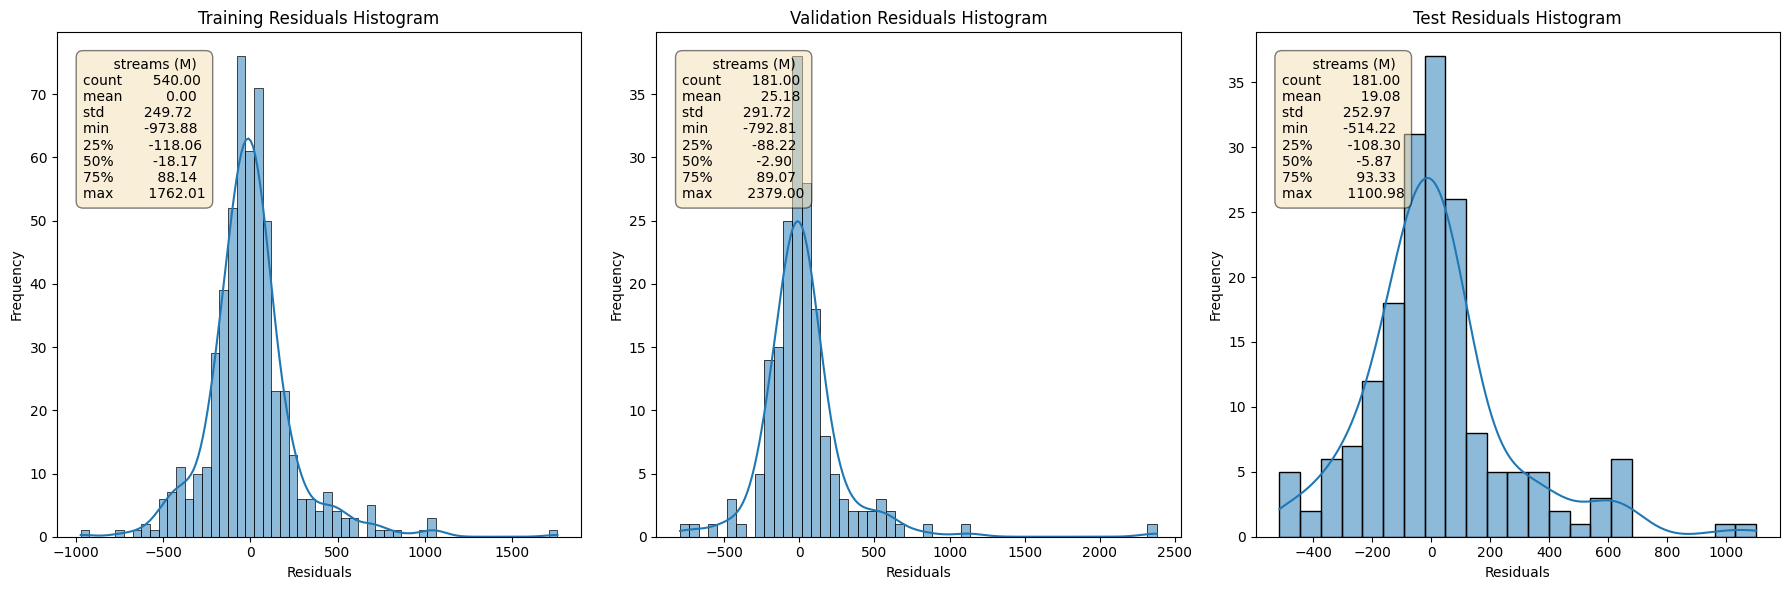

In [39]:
# Calculate residuals for each partition
train_residuals = y_train - y_train_pred
val_residuals = y_val - y_val_pred
test_residuals = y_test - y_test_pred

# Plot histograms of the residuals
fig, axs = plt.subplots(1, 3, figsize=(18, 6)) # Increased figure size for better readability

# Training Residuals
sns.histplot(train_residuals, kde=True, ax=axs[0])
axs[0].set_title('Training Residuals Histogram')
axs[0].set_xlabel('Residuals')
axs[0].set_ylabel('Frequency')
train_stats = pd.DataFrame(train_residuals).describe().round(2) # Round to 2 decimal places
axs[0].text(0.05, 0.95, train_stats.to_string(), transform=axs[0].transAxes, va='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

# Validation Residuals
sns.histplot(val_residuals, kde=True, ax=axs[1])
axs[1].set_title('Validation Residuals Histogram')
axs[1].set_xlabel('Residuals')
axs[1].set_ylabel('Frequency')
val_stats = pd.DataFrame(val_residuals).describe().round(2) # Round to 2 decimal places
axs[1].text(0.05, 0.95, val_stats.to_string(), transform=axs[1].transAxes, va='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

# Test Residuals
sns.histplot(test_residuals, kde=True, ax=axs[2])
axs[2].set_title('Test Residuals Histogram')
axs[2].set_xlabel('Residuals')
axs[2].set_ylabel('Frequency')
test_stats = pd.DataFrame(test_residuals).describe().round(2) # Round to 2 decimal places
axs[2].text(0.05, 0.95, test_stats.to_string(), transform=axs[2].transAxes, va='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))


plt.tight_layout()
plt.show()

In the training and validation partition we have few songs with a residual of -1000 and +1500 which is much more compare to test.

This indicates that a few songs may be outliers and are difficult for the model to predict accurately.

Overall, the residuals are not perfectly normally distributed, likely due to the highly skewed nature of the streams variable and the presence of songs with exceptionally high numbers of streams.

In [40]:
test_stats.head()

,streams (M)
count,181.00
mean,19.08
std,252.97
min,-514.22
25%,-108.30


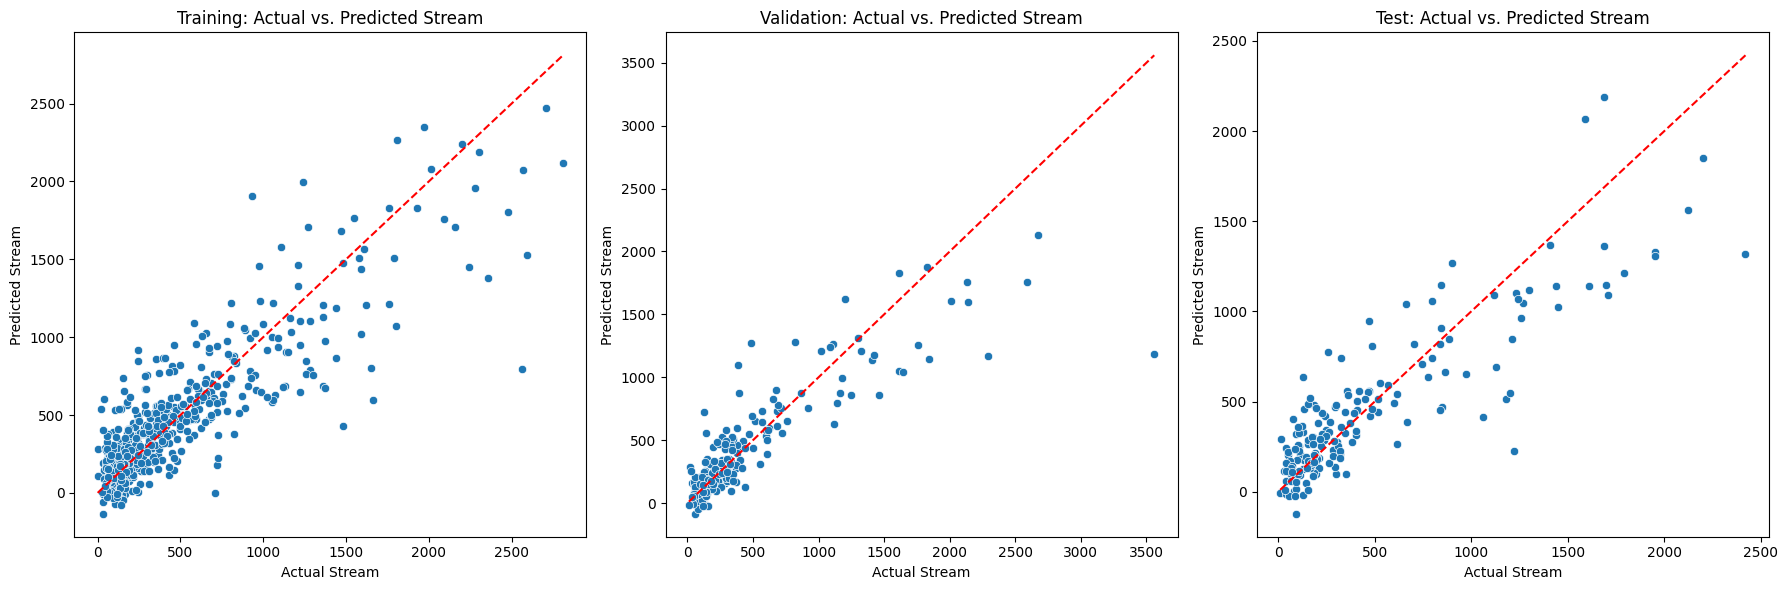

In [41]:
# Create dataframes with actual and predicted stream
# This is to ensure the plotting code has the necessary dataframes
if 'train_results' not in locals() or 'val_results' not in locals() or 'test_results' not in locals():
    train_results = X_train.copy()
    train_results['Actual_stream'] = y_train
    train_results['Predicted_stream'] = y_train_pred

    val_results = X_val.copy()
    val_results['Actual_stream'] = y_val
    val_results['Predicted_stream'] = y_val_pred

    test_results = X_test.copy()
    test_results['Actual_stream'] = y_test
    test_results['Predicted_stream'] = y_test_pred

    print(train_results[['Actual_stream', 'Predicted_stream']].head())

    print("Dataframes with actual and predicted stream created.")

# Plot actual vs. predicted stream for each partition
fig, axs = plt.subplots(1, 3, figsize=(18, 6)) # Increased figure size for better readability

# Training Partition
sns.scatterplot(x='Actual_stream', y='Predicted_stream', data=train_results, ax=axs[0])
axs[0].set_title('Training: Actual vs. Predicted Stream')
axs[0].set_xlabel('Actual Stream')
axs[0].set_ylabel('Predicted Stream')
axs[0].plot([train_results['Actual_stream'].min(), train_results['Actual_stream'].max()],
           [train_results['Actual_stream'].min(), train_results['Actual_stream'].max()],
           color='red', linestyle='--') # Add a diagonal line for reference

# Validation Partition
sns.scatterplot(x='Actual_stream', y='Predicted_stream', data=val_results, ax=axs[1])
axs[1].set_title('Validation: Actual vs. Predicted Stream')
axs[1].set_xlabel('Actual Stream')
axs[1].set_ylabel('Predicted Stream')
axs[1].plot([val_results['Actual_stream'].min(), val_results['Actual_stream'].max()],
           [val_results['Actual_stream'].min(), val_results['Actual_stream'].max()],
           color='red', linestyle='--') # Add a diagonal line for reference

# Test Partition
sns.scatterplot(x='Actual_stream', y='Predicted_stream', data=test_results, ax=axs[2])
axs[2].set_title('Test: Actual vs. Predicted Stream')
axs[2].set_xlabel('Actual Stream')
axs[2].set_ylabel('Predicted Stream')
axs[2].plot([test_results['Actual_stream'].min(), test_results['Actual_stream'].max()],
           [test_results['Actual_stream'].min(), test_results['Actual_stream'].max()],
           color='red', linestyle='--') # Add a diagonal line for reference


plt.tight_layout()
plt.show()

The actual versus predicted plots show a clear positive relationship between actual and predicted streams across the training, validation, and test partitions.

Most observations are reasonably close to the 45-degree reference line, indicating that the model captures a substantial portion of the variation in streams. However, there are several large deviations from the reference line, particularly for songs with very high numbers of streams.

The model appears to have more difficulty predicting these extreme observations.

The similar patterns across all three partitions suggest that the model generalizes reasonably well and does not show substantial overfitting. The increasing spread of predictions at higher stream values may also indicate some heteroscedasticity in the model residuals.

# (7) Check for predictor significance.  Are any predictors insignificant?  Which ones?

P values can help us understand which variables are helpful in forming a prediction and which ones are not.  The smaller the P value, the better the predictor!

In [42]:
X_train.columns

Index(['artist_count', 'Johnson Su Transform to Normal released_year',
       'released_day', 'in_spotify_playlists', 'in_spotify_charts',
       'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists',
       'in_deezer_charts', 'in_shazam_charts', 'bpm', 'danceability_%',
       'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%',
       'liveness_%', 'speechiness_%', 'mode_Minor',
       'released_month_reduced_Low'],
      dtype='object')

In [43]:
# Fit the model using statsmodels to get p-values and other statistics

# Convert boolean columns to integers for statsmodels compatibility
X_train_sm = X_train.copy() # Create a copy to avoid modifying the original X_train
for col in X_train_sm.columns:
    if X_train_sm[col].dtype == bool:
        X_train_sm[col] = X_train_sm[col].astype(int)

# Initialize and fit the OLS model
model_sm = sm.OLS(y_train, X_train_sm).fit()

# Print the summary of the regression results
print(model_sm.summary())

                                 OLS Regression Results                                
Dep. Variable:            streams (M)   R-squared (uncentered):                   0.867
Model:                            OLS   Adj. R-squared (uncentered):              0.862
Method:                 Least Squares   F-statistic:                              169.5
Date:                Mon, 12 Oct 2026   Prob (F-statistic):                   7.29e-213
Time:                        17:07:31   Log-Likelihood:                         -3748.2
No. Observations:                 540   AIC:                                      7536.
Df Residuals:                     520   BIC:                                      7622.
Df Model:                          20                                                  
Covariance Type:            nonrobust                                                  
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------

In [46]:
# Predictors with p-value >= 0.05
insignificant = model_sm.pvalues[model_sm.pvalues >= 0.05]

print("Insignificant predictors:")
print(insignificant)

Insignificant predictors:
artist_count           0.145872
released_day           0.076776
in_apple_charts        0.515988
in_deezer_playlists    0.227369
in_deezer_charts       0.486748
energy_%               0.605802
acousticness_%         0.051733
instrumentalness_%     0.302154
liveness_%             0.600010
speechiness_%          0.500131
mode_Minor             0.633361
dtype: float64


In [47]:
significant = model_sm.pvalues[model_sm.pvalues < 0.05]

print("Significant predictors:")
print(significant)

Significant predictors:
Johnson Su Transform to Normal released_year    2.198941e-21
in_spotify_playlists                            5.754020e-07
in_spotify_charts                               1.272189e-11
in_apple_playlists                              3.428621e-24
in_shazam_charts                                8.602817e-09
bpm                                             3.256397e-02
danceability_%                                  6.903217e-03
valence_%                                       1.689862e-03
released_month_reduced_Low                      1.131136e-02
dtype: float64


Using a significance level of 0.05, nine predictors were found to be statistically significant:

Johnson Su Transform to Normal released_year,
in_spotify_playlists,
in_spotify_charts,

in_apple_playlists, in_shazam_charts, bpm, danceability_%,

valence_%, and released_month_reduced_Low.

All of these predictors have p-values below 0.05. The remaining predictors have p-values greater than or equal to 0.05 and are therefore statistically insignificant.

# (8) Re-train the model using just the statistically significant predictors.

We can also automate our variable selection with methods like backward elimination, forward selection, or a mixed approach.  Below is an example of backward elimination which came to the same conclusion as our manual approach above.  

In [48]:
# Automate variable selection using Backward Elimination based on p-values

def backward_elimination(X, y, significance_level=0.05):
    """
    Performs backward elimination to select features based on p-values.

    Args:
        X (pd.DataFrame): DataFrame of predictor variables.
        y (pd.Series): Series of the target variable.
        significance_level (float): The alpha level for statistical significance.

    Returns:
        list: A list of the selected feature names.
    """
    features = X.columns.tolist()
    while (len(features) > 0):
        # Create a copy and convert boolean columns to integers for statsmodels compatibility
        X_be = X[features].copy()
        for col in X_be.columns:
            if X_be[col].dtype == bool:
                X_be[col] = X_be[col].astype(int)

        X_train_be = sm.add_constant(X_be)
        model_be = sm.OLS(y, X_train_be).fit()
        p_values = model_be.pvalues[1:] # Exclude constant's p-value
        max_p_value = max(p_values)
        if max_p_value > significance_level:
            redundant_feature = p_values.idxmax()
            features.remove(redundant_feature)
        else:
            break
    return features

# Perform backward elimination on the training data
selected_features = backward_elimination(X_train, y_train)

print("Selected features after backward elimination:", selected_features)

# You can now use these selected features to train a new model
X_train_selected = X_train[selected_features]
X_val_selected = X_val[selected_features]
X_test_selected = X_test[selected_features]

# Display the shapes of the selected feature sets
print("\nShape of training data with selected features:", X_train_selected.shape)
print("Shape of validation data with selected features:", X_val_selected.shape)
print("Shape of test data with selected features:", X_test_selected.shape)

Selected features after backward elimination: ['Johnson Su Transform to Normal released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_shazam_charts', 'valence_%', 'energy_%', 'released_month_reduced_Low']

Shape of training data with selected features: (540, 8)
Shape of validation data with selected features: (181, 8)
Shape of test data with selected features: (181, 8)


p-value change for bpm and danceability_%, hence became insignificant in the reduced model, so backward elimination removed them.

# (9) Check model performance again by partition with RMSE, R Squared, distribution of residuals, and actual by predicted plots.

So let's run the model again with fewer predictors and see how it performs.

In [50]:
# Rerun the Linear Regression model with the selected subset of predictors

# Initialize the Linear Regression model
model_selected = LinearRegression()

# Fit the model to the training data with selected features
model_selected.fit(X_train_selected, y_train)

# Make predictions on the training, validation, and test sets with selected features
y_train_pred_selected = model_selected.predict(X_train_selected)
y_val_pred_selected = model_selected.predict(X_val_selected)
y_test_pred_selected = model_selected.predict(X_test_selected)

# Evaluate the new model on the training, validation, and test sets
train_mse_selected = mean_squared_error(y_train, y_train_pred_selected)
val_mse_selected = mean_squared_error(y_val, y_val_pred_selected)
test_mse_selected = mean_squared_error(y_test, y_test_pred_selected)

# Calculate RMSE for the new model
train_rmse_selected = np.sqrt(train_mse_selected)
val_rmse_selected = np.sqrt(val_mse_selected)
test_rmse_selected = np.sqrt(test_mse_selected)

train_r2_selected = r2_score(y_train, y_train_pred_selected)
val_r2_selected = r2_score(y_val, y_val_pred_selected)
test_r2_selected = r2_score(y_test, y_test_pred_selected)

# Print the performance metrics for the new model
print("Model Performance with Selected Features:")
print(f"  Training Set - RMSE: {train_rmse_selected:.2f}, R-squared: {train_r2_selected:.2f}")
print(f"  Validation Set - RMSE: {val_rmse_selected:.2f}, R-squared: {val_r2_selected:.2f}")
print(f"  Test Set - RMSE: {test_rmse_selected:.2f}, R-squared: {test_r2_selected:.2f}")

# Print the model coefficients and intercept for the new model
print("\nModel Coefficients with Selected Features:")
for feature, coef in zip(X_train_selected.columns, model_selected.coef_):
    print(f"  {feature}: {coef:.2f}")

print(f"\nIntercept: {model_selected.intercept_:.2f}")

Model Performance with Selected Features:
  Training Set - RMSE: 252.33, R-squared: 0.75
  Validation Set - RMSE: 297.88, R-squared: 0.73
  Test Set - RMSE: 254.24, R-squared: 0.75

Model Coefficients with Selected Features:
  Johnson Su Transform to Normal released_year: -135.48
  in_spotify_playlists: 0.02
  in_spotify_charts: 6.45
  in_apple_playlists: 2.57
  in_shazam_charts: -0.53
  valence_%: -1.15
  energy_%: -1.58
  released_month_reduced_Low: 55.54

Intercept: 304.47


After backward elimination, the model was reduced to eight statistically significant predictors. The reduced model performed very similarly to the full model.

The test R² remained at 0.75, while test RMSE increased only slightly from 253.00 to 254.24. Validation R² decreased slightly from 0.74 to 0.73.

Therefore, removing the statistically insignificant predictors had very little impact on predictive performance. The reduced model is more parsimonious while maintaining approximately the same predictive accuracy as the full model.

# (10) How did performance change?  Which model is better?

Performance decreased slightly after backward elimination.

The full model had a test RMSE of 253.00 and R² of 0.75, compared with a test RMSE of 254.24 and R² of 0.75 for the selected model. Validation R² decreased from 0.74 to 0.73. Therefore, the full model is slightly better in terms of predictive performance.

However, the selected model uses only eight predictors compared with 19 in the full model and achieves nearly the same performance. Thus, the selected model provides a more parsimonious model with minimal loss in predictive accuracy.